In [1]:
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from clean import shift_images_to_zero, crop_images

# Load Data

In [ ]:
# Get data filepaths
filepaths = sorted(glob.glob("../data/*.npz"))
all_files = {os.path.basename(fp): fp for fp in filepaths}

# Remove held out test image
held_out_image = 'O013490.npz'
filepaths = {k: v for k, v in all_files.items() if k != held_out_image}

In [3]:
# from data.py
images = []
for fp in filepaths.values():
    npz_data = np.load(fp)
    key = list(npz_data.files)[0]
    data = npz_data[key]
    images.append(data)

# General Checks

In [4]:
# Check for NaN values
for image in images:
    if pd.isna(image).any():
        print('NaN detected')

In [ ]:
# Collect all shapes
shapes = []
for image in images:
    shapes.append(image.shape)

shapes = np.array(shapes)

In [6]:
# Check if 161 unlabeled images have 10 columns and 2 labeled images have 11 columns
for num, counts in zip(*np.unique(shapes[:, 1], return_counts=True)):
    print(f'Number of columns: {num}, Count: {counts}')

Number of columns: 10, Count: 161
Number of columns: 11, Count: 2


# Coordinates

In [7]:
Y_COL = 0
X_COL = 1

In [8]:
# Check if any coordinates have non integer values
for image in images:
    has_non_integers = np.any(image[:, Y_COL] % 1 != 0)
    if has_non_integers:
        print('Detected non integers for Y coordinates.')

    has_non_integers = np.any(image[:, X_COL] % 1 != 0)
    if has_non_integers:
        print('Detected non integers for X coordinates.')

In [ ]:
def get_extrema(images):
    # Collect all min and max of X and Y for each image
    y_extrema = []
    x_extrema = []
    for image in images:
        y_extrema.append((
            image[:, Y_COL].min(),
            image[:, Y_COL].max(),
        ))

        x_extrema.append((
            image[:, X_COL].min(),
            image[:, X_COL].max(),
        ))

    y_extrema = np.array(y_extrema)
    x_extrema = np.array(x_extrema)

    return y_extrema, x_extrema

In [10]:
# Print counts of each extrema for each coordinate
y_extrema, x_extrema = get_extrema(images)

for num, counts in zip(*np.unique(y_extrema[:, 0], return_counts=True)):
    print(f'Y Min: {num}, Count: {counts}')
print('-' * 7)

for num, counts in zip(*np.unique(y_extrema[:, 1], return_counts=True)):
    print(f'Y Max: {num}, Count: {counts}')
print('-' * 7)

for num, counts in zip(*np.unique(x_extrema[:, 0], return_counts=True)):
    print(f'X Min: {num}, Count: {counts}')
print('-' * 7)

for num, counts in zip(*np.unique(x_extrema[:, 1], return_counts=True)):
    print(f'X Max: {num}, Count: {counts}')
print('-' * 7)

Y Min: 2.0, Count: 163
-------
Y Max: 383.0, Count: 163
-------
X Min: 57.0, Count: 1
X Min: 58.0, Count: 7
X Min: 59.0, Count: 6
X Min: 60.0, Count: 1
X Min: 61.0, Count: 1
X Min: 62.0, Count: 8
X Min: 63.0, Count: 18
X Min: 64.0, Count: 26
X Min: 65.0, Count: 64
X Min: 66.0, Count: 26
X Min: 67.0, Count: 5
-------
X Max: 361.0, Count: 1
X Max: 362.0, Count: 10
X Max: 363.0, Count: 3
X Max: 364.0, Count: 1
X Max: 366.0, Count: 8
X Max: 367.0, Count: 27
X Max: 368.0, Count: 33
X Max: 369.0, Count: 57
X Max: 370.0, Count: 21
X Max: 371.0, Count: 1
X Max: 373.0, Count: 1
-------


The minimums don't start at 0 for some reason. I will standardize this by subtracting the minimum for each coordinate.

In [11]:
images = shift_images_to_zero(images)

In [ ]:
# Print counts of each extrema for each coordinate in the shifted images
y_extrema, x_extrema = get_extrema(images)

for num, counts in zip(*np.unique(y_extrema[:, 0], return_counts=True)):
    print(f'Y Min: {num}, Count: {counts}')
print('-' * 7)

for num, counts in zip(*np.unique(y_extrema[:, 1], return_counts=True)):
    print(f'Y Max: {num}, Count: {counts}')
print('-' * 7)

for num, counts in zip(*np.unique(x_extrema[:, 0], return_counts=True)):
    print(f'X Min: {num}, Count: {counts}')
print('-' * 7)

for num, counts in zip(*np.unique(x_extrema[:, 1], return_counts=True)):
    print(f'X Max: {num}, Count: {counts}')
print('-' * 7)

Y Min: 0.0, Count: 163
-------
Y Max: 381.0, Count: 163
-------
X Min: 0.0, Count: 163
-------
X Max: 303.0, Count: 40
X Max: 304.0, Count: 119
X Max: 305.0, Count: 3
X Max: 308.0, Count: 1
-------


## Check if coordinates cover the full space for each image

In [13]:
# Check if each image doesn't have more than 1 point per location
def check_image_has_unique_coordinates(image):
    coords = np.asarray(
        image[:, [Y_COL, X_COL]],
        dtype=np.int64,
    )

    return np.unique(coords, axis=0).shape[0] == coords.shape[0]

for i, image in enumerate(images):
    if not check_image_has_unique_coordinates(image):
        print('Detected duplicate coordinate locations.')

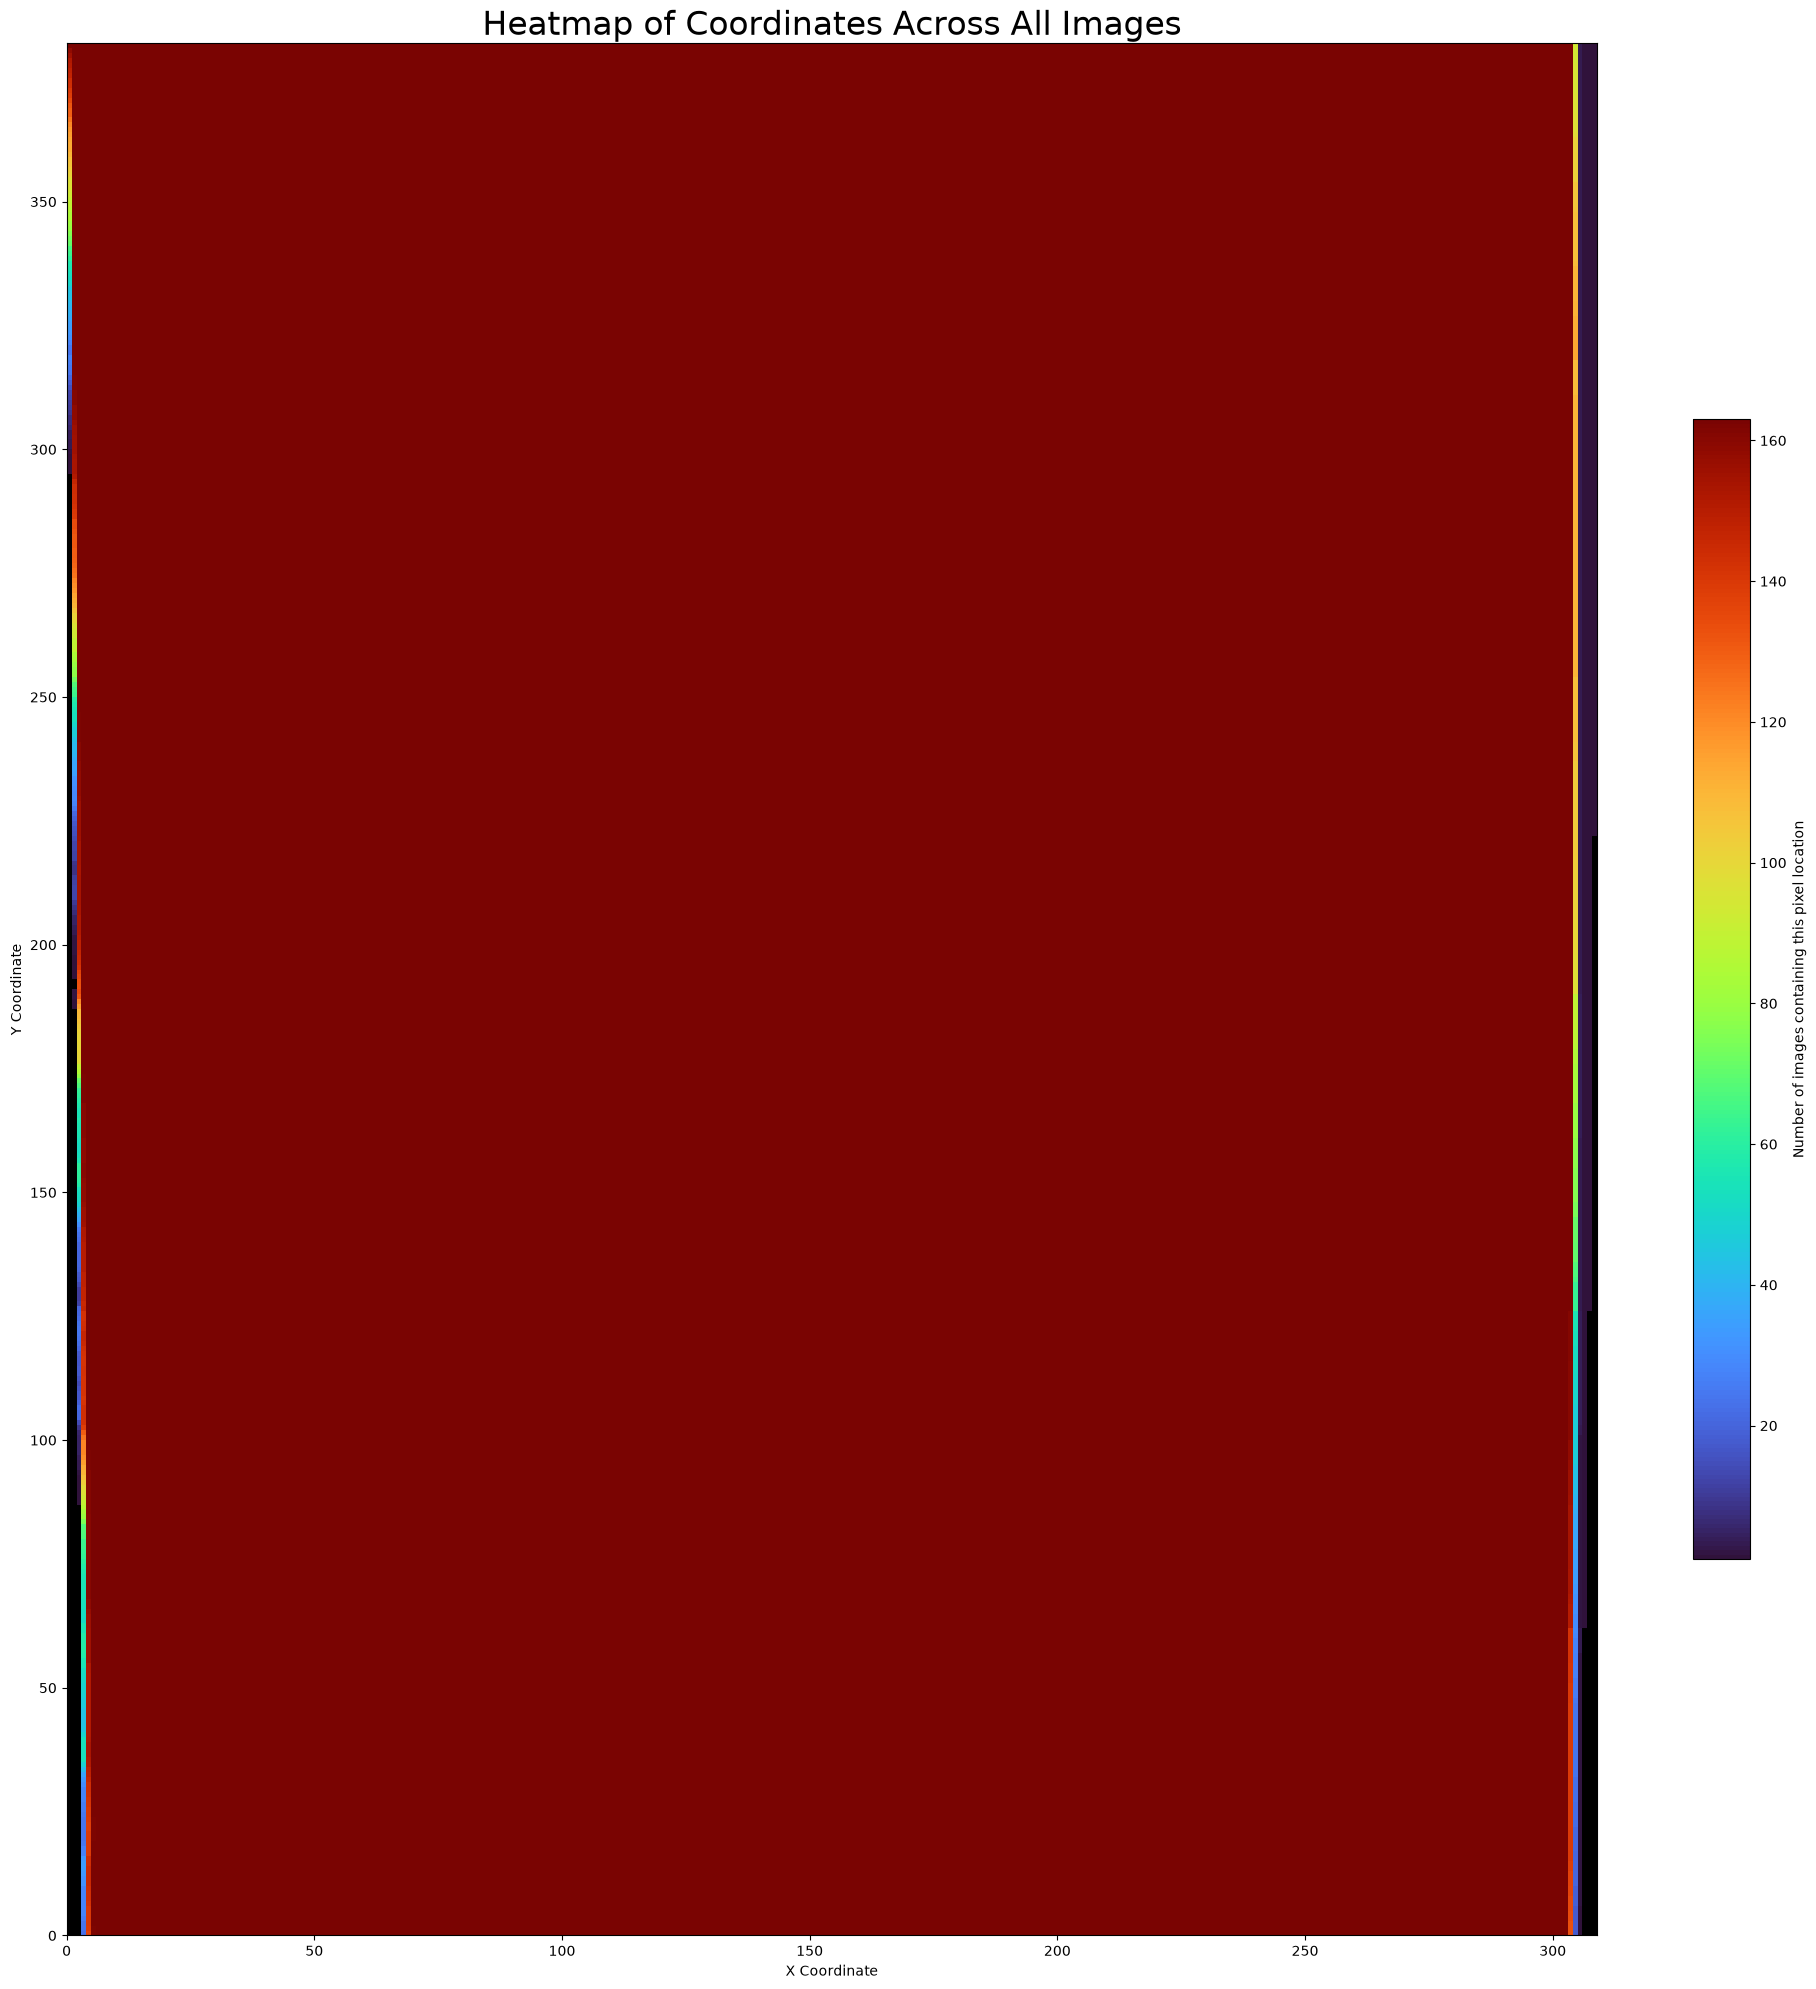

In [14]:
fig, ax = plt.subplots(figsize=(20, 20))
ax.set_title('Heatmap of Coordinates Across All Images', fontsize=24)

max_x = max(int(image[:, X_COL].max()) for image in images)
max_y = max(int(image[:, Y_COL].max()) for image in images)

heatmap = np.zeros((max_x + 1, max_y + 1)) 

for image in images:
    x = image[:, X_COL].astype(np.int64)
    y = image[:, Y_COL].astype(np.int64)

    mask = np.zeros_like(heatmap, dtype=bool)
    mask[x, y] = True
    heatmap += mask

masked = np.ma.masked_where(heatmap == 0, heatmap)

cmap = plt.get_cmap('turbo').copy()
cmap.set_bad(color='black')

im = ax.imshow(
    masked.T,
    origin='lower',
    cmap=cmap,
    vmin=1,
    extent=[0, heatmap.shape[0], 0, heatmap.shape[1]],
)
fig.colorbar(im, ax=ax, label='Number of images containing this pixel location', shrink=0.6)

ax.set_xlabel('X Coordinate')
ax.set_ylabel('Y Coordinate')

plt.tight_layout()
plt.savefig('../figs/clean_pixel_heatmap.pdf', bbox_inches='tight')
plt.show()

This requires a judgement call. If patches are required, it might make sense to convert all images into a standardized square shape. If individual pixels are used, it might be ok to leave it in this "weird" shape.

In [15]:
# Get the rectangle where all images have pixels
coords_in_all = np.array(np.where(heatmap == len(images)))

top_side = coords_in_all[:, coords_in_all[1] == coords_in_all[1].max()]
bottom_side = coords_in_all[:, coords_in_all[1] == coords_in_all[1].min()]

print(f'Top left: ({top_side[0].min()}, {top_side[1].max()})')
print(f'Bottom left: ({bottom_side[0].min()}, {bottom_side[1].min()})')
print(f'Bottom right: ({bottom_side[0].max()}, {bottom_side[1].min()})')
print(f'Top right: ({top_side[0].max()}, {top_side[1].max()})')

Top left: (0, 381)
Bottom left: (6, 0)
Bottom right: (302, 0)
Top right: (303, 381)


In [16]:
# Because this is a slanted rectangle, to make 90 degree rectangle,
# take the max X coord of the left side and min X coord of the right
# side. We do not need to change Y because they are equal.

left_x = max(top_side[0].min(), bottom_side[0].min())
right_x = min(top_side[0].max(), bottom_side[0].max())

print(f'X constraints: ({left_x}, {right_x})')

X constraints: (6, 302)


In [17]:
# Get new cropped images with standardized shape
cropped_images = crop_images(images)

In [ ]:
# Check if all images have valid pixels in the same shape
max_x = max(int(image[:, X_COL].max()) for image in cropped_images)
max_y = max(int(image[:, Y_COL].max()) for image in cropped_images)

heatmap = np.zeros((max_x + 1, max_y + 1)) 

for img in cropped_images:
    x = img[:, X_COL].astype(int)
    y = img[:, Y_COL].astype(int)

    mask = np.zeros_like(heatmap, dtype=bool)
    mask[x, y] = True
    heatmap += mask

print('Do all images have same pixel coordinates?', (heatmap == len(images)).all())

Do all images have same pixel coordinates? True


In [19]:
num_pixels_per_image = [cropped_image.shape[0] for cropped_image in cropped_images]
for num, counts in zip(*np.unique(num_pixels_per_image, return_counts=True)):
    print(f'Number of pixels: {num}, Count: {counts}')

Number of pixels: 113454, Count: 163


In [ ]:
# Print counts of each extrema for each coordinate in the cropped images
y_extrema, x_extrema = get_extrema(cropped_images)

for num, counts in zip(*np.unique(y_extrema[:, 0], return_counts=True)):
    print(f'Y Min: {num}, Count: {counts}')
print('-' * 7)

for num, counts in zip(*np.unique(y_extrema[:, 1], return_counts=True)):
    print(f'Y Max: {num}, Count: {counts}')
print('-' * 7)

for num, counts in zip(*np.unique(x_extrema[:, 0], return_counts=True)):
    print(f'X Min: {num}, Count: {counts}')
print('-' * 7)

for num, counts in zip(*np.unique(x_extrema[:, 1], return_counts=True)):
    print(f'X Max: {num}, Count: {counts}')
print('-' * 7)

Y Min: 0.0, Count: 163
-------
Y Max: 381.0, Count: 163
-------
X Min: 0.0, Count: 163
-------
X Max: 296.0, Count: 163
-------


Cropped images are all 297x382

# Expert Features

In [21]:
NDAI_COL = 2
SD_COL = 3
CORR_COL = 4

In [22]:
# Collect all expert features
all_NDAI_values = []
all_SD_values = []
all_CORR_values = []

for image in images:
    all_NDAI_values.extend(image[:, NDAI_COL])
    all_SD_values.extend(image[:, SD_COL])
    all_CORR_values.extend(image[:, CORR_COL])

all_NDAI_values = np.array(all_NDAI_values)
all_SD_values = np.array(all_SD_values)
all_CORR_values = np.array(all_CORR_values)

In [23]:
# Check if features violate math constraints:
# NDAI: (-1, 1)
# SD: (0, infinity)
# CORR: (-1, 1)
for name, values in [
    ('NDAI', all_NDAI_values),
    ('SD', all_SD_values),
    ('CORR', all_CORR_values),
]:
    print(f'{name}:\t(min, max) = ({values.min()}, {values.max()})')

NDAI:	(min, max) = (-0.6123912334442139, 0.9374210238456726)
SD:	(min, max) = (5.656854152679443, 9729.6826171875)
CORR:	(min, max) = (-0.9765561819076538, 0.984079897403717)


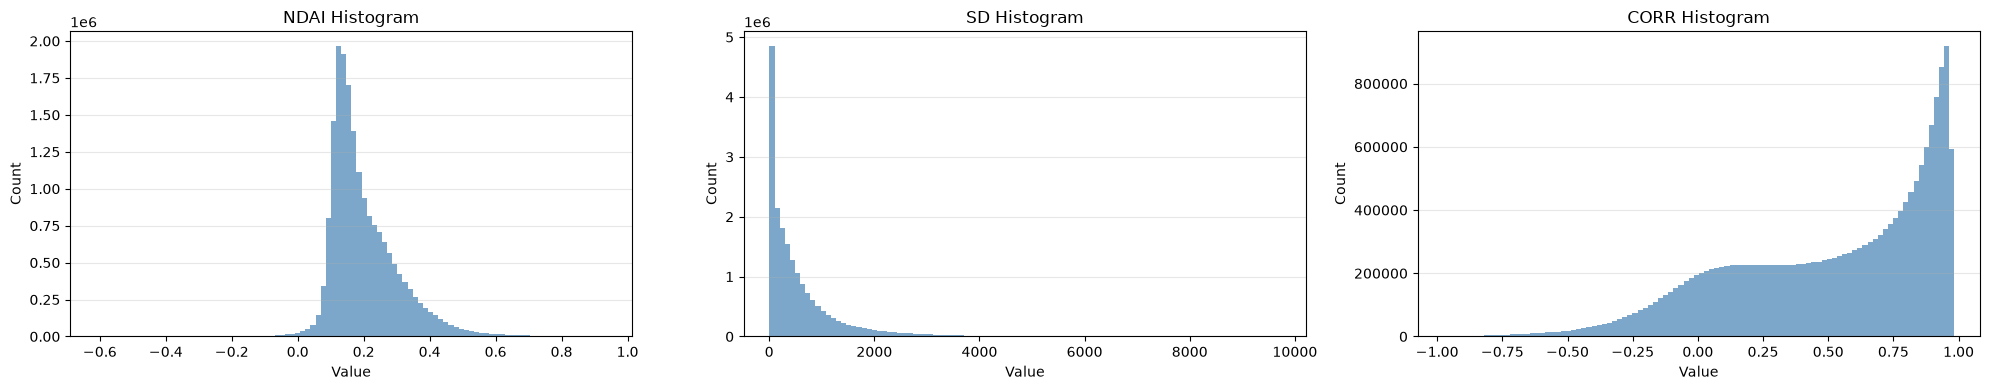

In [24]:
# Check if features follow a usual distribution
feature_data = [
    ('NDAI', all_NDAI_values),
    ('SD', all_SD_values),
    ('CORR', all_CORR_values),
]

fig, axes = plt.subplots(ncols=3, figsize=(20, 4))

for ax, (name, values) in zip(axes, feature_data):
    counts, bin_edges = np.histogram(values, bins=100)
    ax.stairs(counts, bin_edges, fill=True, alpha=0.7, color='steelblue')
    ax.set_xlabel('Value')
    ax.set_ylabel('Count')
    ax.set_title(f'{name} Histogram')
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../figs/clean_features_histograms.pdf', bbox_inches='tight')
plt.show()

# Radiance Angles

In [25]:
DF_COL = 5
CF_COL = 6
BF_COL = 7
AF_COL = 8
AN_COL = 9

In [26]:
# Collect all radiance angles
all_DF_values = []
all_CF_values = []
all_BF_values = []
all_AF_values = []
all_AN_values = []

for image in images:
    all_DF_values.extend(image[:, DF_COL])
    all_CF_values.extend(image[:, CF_COL])
    all_BF_values.extend(image[:, BF_COL])
    all_AF_values.extend(image[:, AF_COL])
    all_AN_values.extend(image[:, AN_COL])

all_DF_values = np.array(all_DF_values)
all_CF_values = np.array(all_CF_values)
all_BF_values = np.array(all_BF_values)
all_AF_values = np.array(all_AF_values)
all_AN_values = np.array(all_AN_values)

In [27]:
# Check if radiance angle coordinates violate non-negativity constraints:
# DF, CF, BF, AF, AN: [0, infinity)
for name, values in [
    ('DF', all_DF_values),
    ('CF', all_CF_values),
    ('BF', all_BF_values),
    ('AF', all_AF_values),
    ('AN', all_AN_values),
]:
    print(f'{name}:\t(min, max) = ({values.min()}, {values.max()})')

DF:	(min, max) = (3086.0, 58074.0)
CF:	(min, max) = (1959.5, 56146.25)
BF:	(min, max) = (1271.75, 37189.5)
AF:	(min, max) = (852.75, 36817.0)
AN:	(min, max) = (705.0, 36411.5)


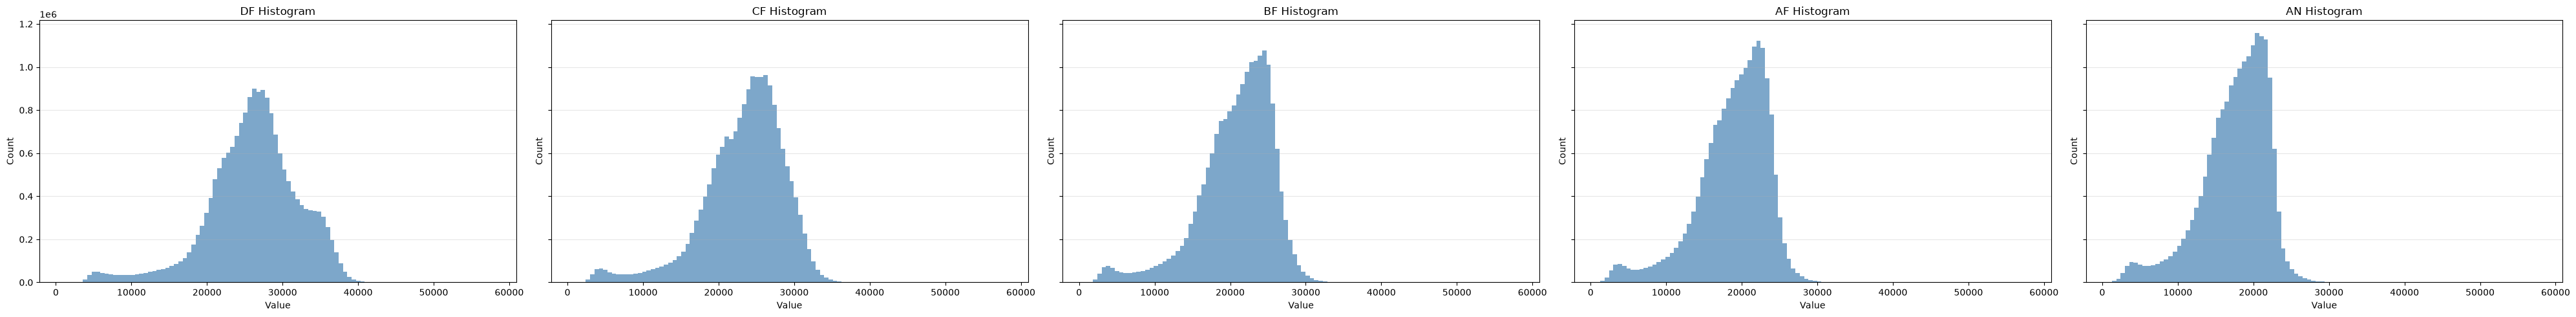

In [28]:
# Check if features follow a usual distribution
feature_data = [
    ('DF', all_DF_values),
    ('CF', all_CF_values),
    ('BF', all_BF_values),
    ('AF', all_AF_values),
    ('AN', all_AN_values),
]

common_min = min(values.min() for _, values in feature_data)
common_max = max(values.max() for _, values in feature_data)
common_bin_edges = np.linspace(common_min, common_max, 101)

fig, axes = plt.subplots(
    ncols=5,
    figsize=(40, 5),
    sharex=True,
    sharey=True,
)

for ax, (name, values) in zip(axes, feature_data):
    counts, bin_edges = np.histogram(values, bins=common_bin_edges)
    ax.stairs(counts, bin_edges, fill=True, alpha=0.7, color='steelblue')
    ax.set_xlabel('Value')
    ax.set_ylabel('Count')
    ax.set_title(f'{name} Histogram')
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../figs/clean_angles_histograms.pdf', bbox_inches='tight')
plt.show()

# Labels

In [29]:
LABEL_COL = 10

In [ ]:
# Labeled images have 11 columns and unlabeled images have 10 columns
labeled_images = [image for image in images if image.shape[1] == 11]

In [31]:
# Collect all labels
all_label_values = []

for image in labeled_images:
    all_label_values.extend(image[:, LABEL_COL])

all_label_values = np.array(all_label_values)

In [32]:
# Check if labels have valid values (-1, 0, 1)
for num, counts in zip(*np.unique(all_label_values, return_counts=True)):
    print(f'Label: {num}, Count: {counts}')

Label: -1.0, Count: 83886
Label: 0.0, Count: 104375
Label: 1.0, Count: 41712
